# Ayudantía 3: de explicar a predecir

Notebook de respaldo de `ayudantia_3.html`. Carga los datos de la PAES 2026, entrena los modelos y reproduce las cifras de la página.

**Datos.** Bases públicas del Proceso de Admisión 2026 del [DEMRE](https://demre.cl/). Copiar en la carpeta `data/` (junto a la carpeta `notebooks/`):

- `PAES.csv` (inscritos y puntajes)
- `B_SOCIOECONOMICO_DOMICILIO_PAES_2026_PUB_MRUN.csv` (datos socioeconómicos)

**Recorrido.**
1. Preparar los datos (lo mismo que en la ayudantía 2).
2. Separar entrenamiento y prueba.
3. Línea base y regresión lineal.
4. KNN.
5. Árbol de decisión.
6. Random forest.
7. Comparación final.
8. k-means de colegios.
9. Anexo: una red neuronal, y el efecto de agregar CLEC.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import root_mean_squared_error

RUTA = '../data/'

## 1. Preparar los datos

Igual que en la ayudantía 2: unir los dos archivos por `MRUN` y convertir los códigos de faltante en `NaN` (0 = no rindió o sin notas, 99 = prefiere no responder, `' '` = vacío).

In [2]:
cols = ['MRUN', 'RBD', 'COD_SEXO', 'FECHA_NACIMIENTO', 'DEPENDENCIA',
        'RAMA_EDUCACIONAL', 'PTJE_NEM', 'MATE1_MAX', 'CLEC_MAX']
paes = pd.read_csv(RUTA + 'PAES.csv', sep=';', usecols=cols, na_values=[' '], low_memory=False)
socio = pd.read_csv(RUTA + 'B_SOCIOECONOMICO_DOMICILIO_PAES_2026_PUB_MRUN.csv', sep=';',
                    usecols=['MRUN', 'INGRESO_PERCAPITA_GRUPO_FA'])

df = paes.merge(socio, on='MRUN')
df = df.rename(columns={'MATE1_MAX': 'M1', 'CLEC_MAX': 'CLEC', 'PTJE_NEM': 'NEM',
                        'INGRESO_PERCAPITA_GRUPO_FA': 'DECIL'})
df.shape

(320087, 10)

In [3]:
# códigos de faltante → NaN
for c in ['M1', 'CLEC', 'NEM']:
    df[c] = df[c].replace(0, np.nan)
df['DECIL'] = df['DECIL'].replace(99, np.nan)

# variables derivadas
df['EDAD'] = 2025 - df['FECHA_NACIMIENTO'] // 100          # FECHA_NACIMIENTO viene como AAAAMM
df.loc[df['EDAD'] < 15, 'EDAD'] = np.nan                     # edades imposibles
df['MUJER'] = (df['COD_SEXO'] == 2).astype(int)

# dummies (NaN se mantiene si el dato original falta)
df['TP'] = (df['RAMA_EDUCACIONAL'].str[0] == 'T').astype(float).where(df['RAMA_EDUCACIONAL'].notna())
df['PAGADO'] = (df['DEPENDENCIA'] == 4).astype(float).where(df['DEPENDENCIA'].notna())
df['SUBV'] = (df['DEPENDENCIA'] == 3).astype(float).where(df['DEPENDENCIA'].notna())

## 2. Separar entrenamiento y prueba

Queremos **predecir** M1 para personas que el modelo no vio. Por eso guardamos una parte de los datos (la *prueba*) que solo se usa al final para medir el error.

Para que todo corra rápido en clases usamos una muestra de 20.000 casos completos.

In [4]:
X_cols = ['NEM', 'DECIL', 'PAGADO', 'SUBV', 'TP', 'MUJER', 'EDAD']

completos = df.dropna(subset=X_cols + ['M1'])
muestra = completos.sample(20000, random_state=42)

X = muestra[X_cols]
y = muestra['M1']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

len(completos), X_train.shape, X_test.shape

(194612, (15000, 7), (5000, 7))

In [5]:
# función auxiliar: RMSE en entrenamiento y en prueba
def evaluar(modelo):
    modelo.fit(X_train, y_train)
    rmse_train = root_mean_squared_error(y_train, modelo.predict(X_train))
    rmse_test = root_mean_squared_error(y_test, modelo.predict(X_test))
    return round(rmse_train, 1), round(rmse_test, 1)

## 3. Línea base y regresión lineal

La **línea base** predice siempre el promedio de M1 en entrenamiento. Cualquier modelo que valga la pena tiene que ganarle.

In [6]:
base = root_mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
round(base, 1)

147.4

In [7]:
lineal = LinearRegression()
evaluar(lineal)

(113.2, 114.4)

In [8]:
# los coeficientes son los mismos que daría statsmodels
pd.Series(lineal.coef_, index=X_cols).round(2)

NEM         0.50
DECIL       2.64
PAGADO    127.05
SUBV       27.76
TP        -44.16
MUJER     -69.48
EDAD        0.80
dtype: float64

## 4. KNN: los k vecinos más cercanos

Para predecir a una persona, KNN busca las `k` personas de entrenamiento más parecidas y promedia su M1.

"Parecidas" se mide con distancia, así que **hay que escalar**: sin escalar, el NEM (100 a 1000) domina sobre las dummies (0 o 1).

In [9]:
sin_escalar = KNeighborsRegressor(n_neighbors=50)
con_escalar = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=50))

evaluar(sin_escalar), evaluar(con_escalar)

((118.0, 121.3), (107.2, 110.5))

In [10]:
# curva de error según k
ks = [1, 2, 5, 10, 20, 50, 100, 200, 500]
curva_knn = pd.DataFrame(
    [evaluar(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))) for k in ks],
    index=ks, columns=['train', 'test'])
curva_knn

,train,test
1,86.1,152.3
2,85.5,132.6
5,96.0,118.4
10,101.8,113.6
20,104.7,111.6
50,107.2,110.5
100,108.6,110.9
200,110.2,112.3
500,114.2,115.7


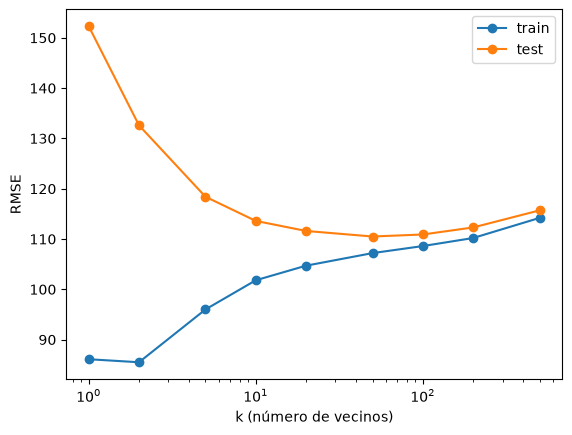

In [11]:
ax = curva_knn.plot(marker='o', logx=True)
ax.set_xlabel('k (número de vecinos)')
ax.set_ylabel('RMSE');

Con `k = 1` el error de entrenamiento es bajo, pero el de prueba es el peor: el modelo memoriza (**sobreajuste**). Con `k` muy grande ambos errores suben porque se promedia casi todo (**subajuste**). El mejor punto está en el medio.

> Ojo: elegir `k` mirando el error de prueba hace que ese error sea un poco optimista. Lo correcto es elegirlo con validación cruzada (`GridSearchCV`) y usar la prueba solo al final.

## 5. Árbol de decisión

Un árbol hace preguntas del tipo "¿NEM ≤ 800?" y predice el promedio de M1 en cada hoja. La profundidad (`max_depth`) controla cuántas preguntas encadena.

In [12]:
profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]
curva_arbol = pd.DataFrame(
    [evaluar(DecisionTreeRegressor(max_depth=d, random_state=0)) for d in profundidades],
    index=profundidades, columns=['train', 'test'])
curva_arbol

,train,test
1,132.1,131.4
2,124.2,125.4
3,120.0,121.5
4,115.3,117.0
5,112.3,114.8
6,110.1,113.7
8,105.4,114.5
10,100.1,116.5
15,79.6,134.4
20,62.5,146.7


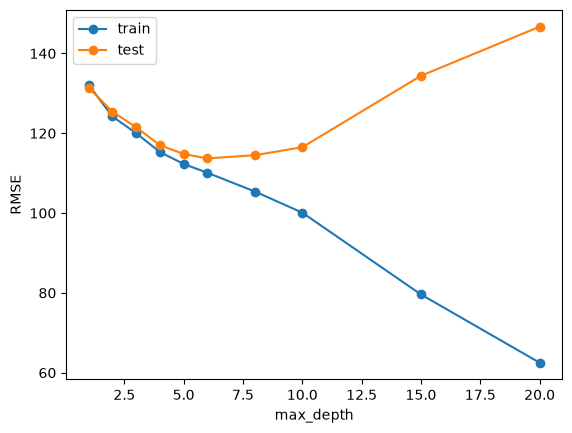

In [13]:
ax = curva_arbol.plot(marker='o')
ax.set_xlabel('max_depth')
ax.set_ylabel('RMSE');

In [14]:
# un árbol chico se puede leer como reglas
arbol3 = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_train, y_train)
print(export_text(arbol3, feature_names=X_cols, decimals=0))

|--- NEM <= 792
|   |--- PAGADO <= 0
|   |   |--- MUJER <= 0
|   |   |   |--- value: [603]
|   |   |--- MUJER >  0
|   |   |   |--- value: [554]
|   |--- PAGADO >  0
|   |   |--- MUJER <= 0
|   |   |   |--- value: [735]
|   |   |--- MUJER >  0
|   |   |   |--- value: [648]
|--- NEM >  792
|   |--- PAGADO <= 0
|   |   |--- NEM <= 898
|   |   |   |--- value: [668]
|   |   |--- NEM >  898
|   |   |   |--- value: [753]
|   |--- PAGADO >  0
|   |   |--- NEM <= 860
|   |   |   |--- value: [805]
|   |   |--- NEM >  860
|   |   |   |--- value: [887]



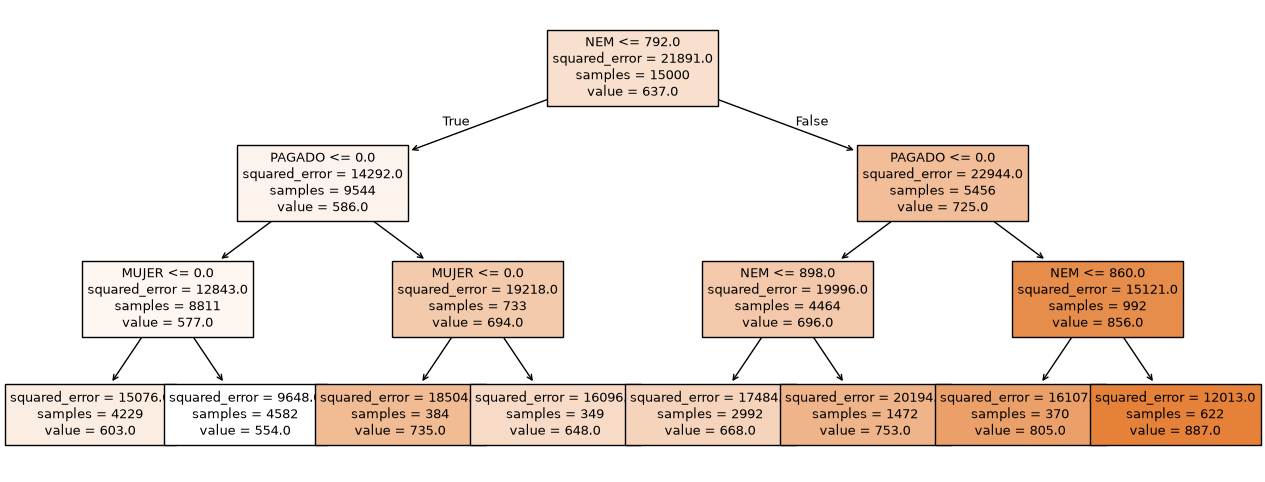

In [15]:
plt.figure(figsize=(16, 6))
plot_tree(arbol3, feature_names=X_cols, filled=True, precision=0, fontsize=9);

## 6. Random forest

Un bosque entrena muchos árboles, cada uno con una muestra distinta de los datos (y de las variables), y promedia sus predicciones.

In [16]:
# con los valores por defecto los árboles crecen hasta el final
bosque_defecto = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1)
evaluar(bosque_defecto)

(68.3, 121.9)

¡Peor que la regresión lineal! Cada árbol crece hasta tener hojas de una sola persona y memoriza el ruido. Promediar 200 árboles sobreajustados ayuda, pero no lo suficiente. Hay que exigir hojas con más personas:

In [17]:
hojas = [1, 5, 10, 20, 50, 100]
curva_bosque = pd.DataFrame(
    [evaluar(RandomForestRegressor(n_estimators=200, min_samples_leaf=h, random_state=0, n_jobs=-1)) for h in hojas],
    index=hojas, columns=['train', 'test'])
curva_bosque

,train,test
1,68.3,121.9
5,93.2,112.8
10,99.7,111.2
20,103.9,110.9
50,107.2,111.1
100,109.0,111.6


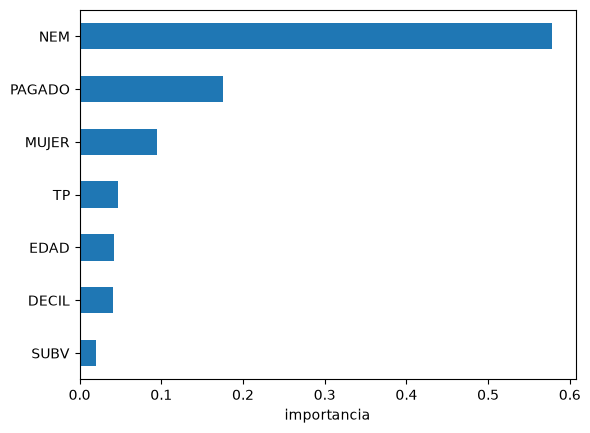

In [18]:
bosque = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=0, n_jobs=-1)
evaluar(bosque)

# importancia de cada variable (suma 1)
pd.Series(bosque.feature_importances_, index=X_cols).sort_values().plot.barh()
plt.xlabel('importancia');

## 7. Comparación final (RMSE en prueba)

In [19]:
resumen = pd.Series({
    'línea base (promedio)': round(base, 1),
    'regresión lineal': evaluar(LinearRegression())[1],
    'KNN (k=50, escalado)': evaluar(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=50)))[1],
    'árbol (max_depth=6)': evaluar(DecisionTreeRegressor(max_depth=6, random_state=0))[1],
    'random forest (por defecto)': evaluar(RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1))[1],
    'random forest (min_samples_leaf=20)': evaluar(bosque)[1],
}, name='RMSE test')
resumen

línea base (promedio)                  147.4
regresión lineal                       114.4
KNN (k=50, escalado)                   110.5
árbol (max_depth=6)                    113.7
random forest (por defecto)            121.9
random forest (min_samples_leaf=20)    110.9
Name: RMSE test, dtype: float64

Todos los modelos razonables quedan cerca de 110–115 puntos. Con estas siete variables hay un límite a lo que se puede predecir: el resto de la variación de M1 depende de cosas que no están en los datos.

## 8. k-means de colegios

Cambiamos de pregunta: sin decirle al modelo qué colegios son científico-humanistas (HC) o técnico-profesionales (TP), ¿qué grupos encuentra?

Primero resumimos por colegio (`RBD`), usando solo colegios con al menos 20 estudiantes.

In [20]:
rindieron = df.dropna(subset=['M1', 'NEM', 'RBD'])
colegios = rindieron.groupby('RBD').agg(
    n=('M1', 'size'),
    M1=('M1', 'mean'),
    NEM=('NEM', 'mean'),
    prop_TP=('TP', 'mean'),
)
colegios = colegios[colegios['n'] >= 20]

# tipo de colegio según la proporción de estudiantes TP
colegios['TIPO'] = np.select([colegios['prop_TP'] < 0.2, colegios['prop_TP'] > 0.8],
                             ['HC', 'TP'], 'Polivalente')
colegios['TIPO'].value_counts()

TIPO
HC             2071
TP              466
Polivalente     343
Name: count, dtype: int64

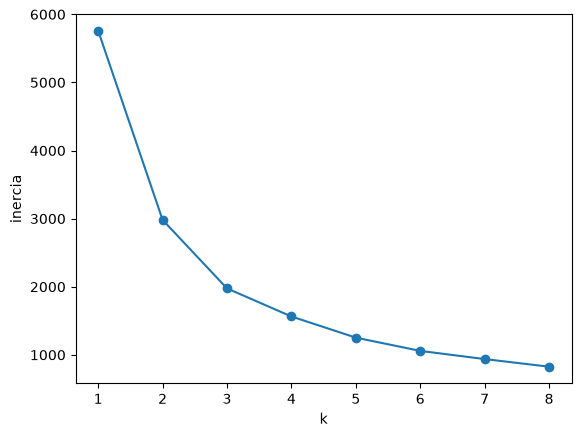

In [21]:
# k-means usa distancias: también hay que escalar
Z = StandardScaler().fit_transform(colegios[['M1', 'NEM']])

# método del codo: inercia (suma de distancias al centro del grupo) según k
inercias = {k: KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z).inertia_ for k in range(1, 9)}
pd.Series(inercias).plot(marker='o', xlabel='k', ylabel='inercia');

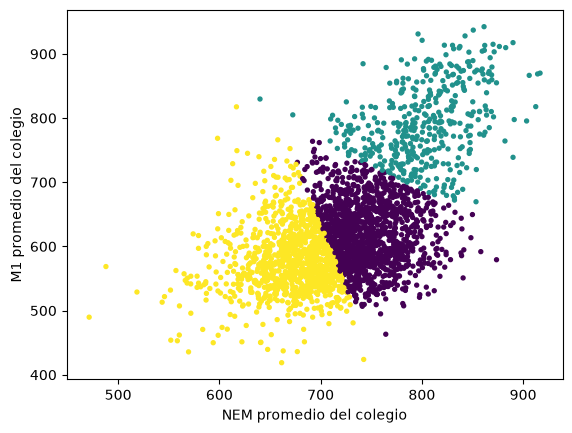

In [22]:
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(Z)
colegios['grupo'] = km.labels_

plt.scatter(colegios['NEM'], colegios['M1'], c=colegios['grupo'], s=8, cmap='viridis')
plt.xlabel('NEM promedio del colegio')
plt.ylabel('M1 promedio del colegio');

In [23]:
# ¿coinciden los grupos con el tipo de colegio?
pd.crosstab(colegios['grupo'], colegios['TIPO'])

TIPO,HC,Polivalente,TP
grupo,,,
0,1070,160,134
1,419,1,0
2,582,182,332


In [24]:
# perfil de cada grupo
colegios.groupby('grupo')[['M1', 'NEM', 'prop_TP', 'n']].mean().round(1)

,M1,NEM,prop_TP,n
grupo,,,,
0,621.0,747.2,0.2,94.7
1,791.1,802.9,0.0,98.6
2,577.6,671.3,0.4,84.8


k-means encuentra grupos por **nivel de rendimiento**, no por tipo de colegio. Los colegios TP quedan casi todos en los grupos de rendimiento bajo y medio, pero esos grupos también tienen muchos colegios HC. Un algoritmo no supervisado encuentra la estructura más fuerte de los datos, que no tiene por qué ser la etiqueta que teníamos en mente.

## 9. Anexo: una red neuronal

Una **neurona** hace una regresión lineal con sus entradas y le aplica una función de activación (aquí ReLU: \(\max(0, z)\)). Una **capa** son varias neuronas en paralelo, y una **red** encadena capas: las salidas de una son las entradas de la siguiente. La red se entrena en **épocas**: en cada época recorre los datos de entrenamiento y ajusta sus pesos para bajar el error.

`MLPRegressor` se usa igual que los demás modelos. Como trabaja con pesos y distancias, también hay que escalar.

In [25]:
from sklearn.neural_network import MLPRegressor

red = make_pipeline(StandardScaler(),
                    MLPRegressor(hidden_layer_sizes=(32, 16),   # dos capas ocultas: 32 y 16 neuronas
                                 early_stopping=True,           # separa 10% de train para validar y se detiene
                                 max_iter=500, random_state=0))
evaluar(red)

(108.0, 109.8)

102

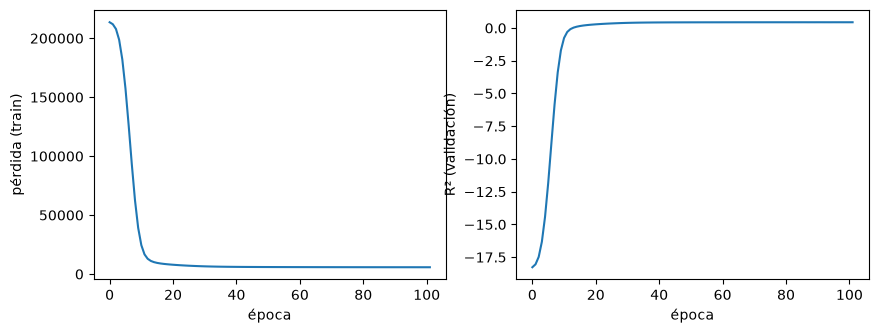

In [26]:
# pérdida por época (entrenamiento) y R² en la validación interna
mlp = red[-1]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(mlp.loss_curve_); ax[0].set_xlabel('época'); ax[0].set_ylabel('pérdida (train)')
ax[1].plot(mlp.validation_scores_); ax[1].set_xlabel('época'); ax[1].set_ylabel('R² (validación)');
mlp.n_iter_

La red queda apenas mejor que KNN y el bosque. Con estas siete variables, ningún modelo pasa de ~110 puntos de error.

### 9.1 ¿Y si agregamos el puntaje de CLEC?

CLEC (Competencia Lectora) está muy correlacionado con M1 (\(r = 0.74\)). Lo agregamos como octava variable y repetimos **todos** los modelos.

CLEC falta en 136 personas de la muestra (no rindieron la prueba). Para comparar con y sin CLEC sobre **las mismas personas**, las sacamos de entrenamiento y prueba.

In [27]:
cols_clec = X_cols + ['CLEC']

con_clec = muestra['CLEC'].notna()
idx_train = X_train.index[con_clec[X_train.index]]
idx_test = X_test.index[con_clec[X_test.index]]

def evaluar_cols(modelo, cols):
    modelo.fit(muestra.loc[idx_train, cols], muestra.loc[idx_train, 'M1'])
    pred = modelo.predict(muestra.loc[idx_test, cols])
    return round(root_mean_squared_error(muestra.loc[idx_test, 'M1'], pred), 1)

len(idx_train), len(idx_test)

(14899, 4965)

In [28]:
modelos = {
    'regresión lineal': lambda: LinearRegression(),
    'KNN (k=50, escalado)': lambda: make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=50)),
    'árbol (max_depth=6)': lambda: DecisionTreeRegressor(max_depth=6, random_state=0),
    'random forest (min_samples_leaf=20)': lambda: RandomForestRegressor(n_estimators=200, min_samples_leaf=20,
                                                                         random_state=0, n_jobs=-1),
    'red neuronal (32, 16)': lambda: make_pipeline(StandardScaler(),
                                                   MLPRegressor(hidden_layer_sizes=(32, 16), early_stopping=True,
                                                                max_iter=500, random_state=0)),
}

tabla = pd.DataFrame({
    'sin CLEC': {nombre: evaluar_cols(crear(), X_cols) for nombre, crear in modelos.items()},
    'con CLEC': {nombre: evaluar_cols(crear(), cols_clec) for nombre, crear in modelos.items()},
})
tabla['mejora'] = tabla['sin CLEC'] - tabla['con CLEC']
tabla

,sin CLEC,con CLEC,mejora
regresión lineal,114.0,90.2,23.8
"KNN (k=50, escalado)",110.0,90.8,19.2
árbol (max_depth=6),112.9,91.6,21.3
random forest (min_samples_leaf=20),110.5,88.9,21.6
"red neuronal (32, 16)",111.3,88.9,22.4


Agregar **una variable con información nueva** baja el error de todos los modelos mucho más que cambiar de modelo: de ~110 a ~90 puntos. Eso es lo que se ganaba antes probando modelos cada vez más complejos, multiplicado por cinco.

Ojo con la interpretación: predecir un puntaje PAES con otro puntaje PAES de la misma persona no responde la pregunta original (qué del colegio o del hogar se asocia con M1). Es útil para ver cuánto pesa tener la variable correcta.